In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
data_path = "/content/drive/MyDrive/AutoSenseAI/data/vehicle_maintenance_data.csv"

df = pd.read_csv(data_path)

print("Shape:", df.shape)
df.head()

Shape: (50000, 20)


,Vehicle_Model,Mileage,Maintenance_History,Reported_Issues,Vehicle_Age,Fuel_Type,Transmission_Type,Engine_Size,Odometer_Reading,Last_Service_Date,Warranty_Expiry_Date,Owner_Type,Insurance_Premium,Service_History,Accident_History,Fuel_Efficiency,Tire_Condition,Brake_Condition,Battery_Status,Need_Maintenance
0,Truck,58765,Good,0,4,Electric,Automatic,2000,28524,2023-11-23,2025-06-24,Second,20782,6,3,13.622204,New,New,Weak,1
1,Van,60353,Average,1,7,Electric,Automatic,2500,133630,2023-09-21,2025-06-04,Second,23489,7,0,13.625307,New,New,Weak,1
2,Bus,68072,Poor,0,2,Electric,Automatic,1500,34022,2023-06-27,2025-04-27,First,17979,7,0,14.306302,New,Good,Weak,1
3,Bus,60849,Average,4,5,Petrol,Automatic,2500,81636,2023-08-24,2025-11-05,Second,6220,7,3,18.709467,New,Worn Out,New,1
4,Bus,45742,Poor,5,1,Petrol,Manual,2000,97162,2023-05-25,2025-09-14,Third,16446,6,2,16.977482,Good,Good,Weak,1


In [4]:
target = "Need_Maintenance"

print(df[target].value_counts())
print()
print((df[target].value_counts(normalize=True) * 100).round(2))

Need_Maintenance
1    40498
0     9502
Name: count, dtype: int64

Need_Maintenance
1    81.0
0    19.0
Name: proportion, dtype: float64


In [5]:
condition_features = [
    "Maintenance_History",
    "Service_History",
    "Accident_History",
    "Tire_Condition",
    "Brake_Condition",
    "Battery_Status",
    "Reported_Issues"
]

condition_features

['Maintenance_History',
 'Service_History',
 'Accident_History',
 'Tire_Condition',
 'Brake_Condition',
 'Battery_Status',
 'Reported_Issues']

In [6]:
battery_table = pd.crosstab(
    df["Battery_Status"],
    df[target],
    normalize="index"
).round(4)

battery_table

Need_Maintenance,0,1
Battery_Status,,
Good,0.2833,0.7167
New,0.2860,0.7140
Weak,0.0000,1.0000


In [7]:
battery_rate = (
    df.groupby("Battery_Status")[target]
      .agg(["count", "mean"])
      .sort_values("mean", ascending=False)
)

battery_rate["maintenance_rate_percent"] = (
    battery_rate["mean"] * 100
).round(2)

battery_rate

,count,mean,maintenance_rate_percent
Battery_Status,,,
Weak,16618,1.000000,100.00
Good,16657,0.716696,71.67
New,16725,0.714021,71.40


In [8]:
brake_rate = (
    df.groupby("Brake_Condition")[target]
      .agg(["count", "mean"])
      .sort_values("mean", ascending=False)
)

brake_rate["maintenance_rate_percent"] = (
    brake_rate["mean"] * 100
).round(2)

brake_rate

,count,mean,maintenance_rate_percent
Brake_Condition,,,
Worn Out,16685,1.000000,100.00
New,16668,0.717183,71.72
Good,16647,0.712381,71.24


In [9]:
maintenance_history_rate = (
    df.groupby("Maintenance_History")[target]
      .agg(["count", "mean"])
      .sort_values("mean", ascending=False)
)

maintenance_history_rate["maintenance_rate_percent"] = (
    maintenance_history_rate["mean"] * 100
).round(2)

maintenance_history_rate

,count,mean,maintenance_rate_percent
Maintenance_History,,,
Poor,16564,0.870925,87.09
Average,16724,0.812784,81.28
Good,16712,0.746709,74.67


In [10]:
tire_rate = (
    df.groupby("Tire_Condition")[target]
      .agg(["count", "mean"])
      .sort_values("mean", ascending=False)
)

tire_rate["maintenance_rate_percent"] = (
    tire_rate["mean"] * 100
).round(2)

tire_rate

,count,mean,maintenance_rate_percent
Tire_Condition,,,
Good,16553,0.813025,81.30
New,16825,0.809985,81.00
Worn Out,16622,0.806882,80.69


In [11]:
reported_issue_rate = (
    df.groupby("Reported_Issues")[target]
      .agg(["count", "mean"])
      .sort_index()
)

reported_issue_rate["maintenance_rate_percent"] = (
    reported_issue_rate["mean"] * 100
).round(2)

reported_issue_rate

,count,mean,maintenance_rate_percent
Reported_Issues,,,
0,8317,0.629313,62.93
1,8457,0.618304,61.83
2,8275,0.743927,74.39
3,8268,0.870343,87.03
4,8355,1.000000,100.00
5,8328,1.000000,100.00


In [12]:
def build_preprocessor(dataframe, features):
    categorical = [
        col for col in features
        if dataframe[col].dtype == "object"
    ]

    numerical = [
        col for col in features
        if col not in categorical
    ]

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    return ColumnTransformer([
        ("categorical", categorical_pipeline, categorical),
        ("numerical", numerical_pipeline, numerical)
    ])

In [13]:
train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.20,
    random_state=42,
    stratify=df[target]
)

y_train = df[target].iloc[train_idx]
y_test = df[target].iloc[test_idx]

print("Train:", len(train_idx))
print("Test:", len(test_idx))

Train: 40000
Test: 10000


In [14]:
def evaluate_binary_model(name, model, X_test, y_test):
    pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        prob = model.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, prob)
    else:
        prob = None
        auc = np.nan

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "Precision Positive": precision_score(
            y_test, pred, pos_label=1, zero_division=0
        ),
        "Recall Positive": recall_score(
            y_test, pred, pos_label=1, zero_division=0
        ),
        "Recall Negative": recall_score(
            y_test, pred, pos_label=0, zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "ROC AUC": auc
    }

In [15]:
single_feature_results = []

for feature in condition_features:

    X = df[[feature]]

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    pipeline = Pipeline([
        (
            "preprocessor",
            build_preprocessor(df, [feature])
        ),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=4,
                random_state=42
            )
        )
    ])

    pipeline.fit(X_train, y_train)

    metrics = evaluate_binary_model(
        feature,
        pipeline,
        X_test,
        y_test
    )

    single_feature_results.append(metrics)

single_feature_df = pd.DataFrame(single_feature_results)

single_feature_df.sort_values(
    "Balanced Accuracy",
    ascending=False
)

,Model,Accuracy,Balanced Accuracy,Precision Positive,Recall Positive,Recall Negative,Macro F1,ROC AUC
0,Maintenance_History,0.81,0.5,0.81,1.0,0.0,0.447514,0.587795
1,Service_History,0.81,0.5,0.81,1.0,0.0,0.447514,0.582698
2,Accident_History,0.81,0.5,0.81,1.0,0.0,0.447514,0.560388
3,Tire_Condition,0.81,0.5,0.81,1.0,0.0,0.447514,0.499721
4,Brake_Condition,0.81,0.5,0.81,1.0,0.0,0.447514,0.713665
5,Battery_Status,0.81,0.5,0.81,1.0,0.0,0.447514,0.705091
6,Reported_Issues,0.81,0.5,0.81,1.0,0.0,0.447514,0.780768


In [16]:
enriched_features = [
    "Vehicle_Model",
    "Mileage",
    "Vehicle_Age",
    "Fuel_Type",
    "Transmission_Type",
    "Engine_Size",
    "Reported_Issues",
    "Maintenance_History",
    "Service_History",
    "Accident_History",
    "Tire_Condition",
    "Brake_Condition",
    "Battery_Status"
]

X = df[enriched_features]

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

In [17]:
shallow_tree_pipeline = Pipeline([
    (
        "preprocessor",
        build_preprocessor(df, enriched_features)
    ),
    (
        "classifier",
        DecisionTreeClassifier(
            max_depth=3,
            random_state=42
        )
    )
])

shallow_tree_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Vehicle_Model', 'Fuel_Type',
                                                   'Transmission_Type',
                                                   'Maintenance_History',
                                                   'Tire_Condition',
                                                   'Brake_Condition',
                                                   'Battery_Status']),
                                                 ('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Mileage', 'Vehicle_Age',
                                                   'Engine_Size',
                                                   'Reported_Issues',
                                                   'Service_History',
                                                   'Accident_History'])])),
                ('classifier',
                 DecisionTreeClassifier(max_depth=3, random_state=42))])

In [18]:
shallow_metrics = evaluate_binary_model(
    "Shallow Decision Tree",
    shallow_tree_pipeline,
    X_test,
    y_test
)

shallow_metrics

{'Model': 'Shallow Decision Tree',
 'Accuracy': 0.9272,
 'Balanced Accuracy': np.float64(0.9109486679662118),
 'Precision Positive': 0.9719590268886044,
 'Recall Positive': 0.9371604938271605,
 'Recall Negative': 0.8847368421052632,
 'Macro F1': 0.8881237523416405,
 'ROC AUC': np.float64(0.9623119233268356)}

In [19]:
preprocessor = shallow_tree_pipeline.named_steps["preprocessor"]
tree_model = shallow_tree_pipeline.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()

rules = export_text(
    tree_model,
    feature_names=list(feature_names)
)

print(rules)

|--- numerical__Reported_Issues <= 2.50
|   |--- categorical__Brake_Condition_Worn Out <= 0.50
|   |   |--- categorical__Battery_Status_Weak <= 0.50
|   |   |   |--- class: 0
|   |   |--- categorical__Battery_Status_Weak >  0.50
|   |   |   |--- class: 1
|   |--- categorical__Brake_Condition_Worn Out >  0.50
|   |   |--- class: 1
|--- numerical__Reported_Issues >  2.50
|   |--- numerical__Reported_Issues <= 3.50
|   |   |--- categorical__Maintenance_History_Good <= 0.50
|   |   |   |--- class: 1
|   |   |--- categorical__Maintenance_History_Good >  0.50
|   |   |   |--- class: 1
|   |--- numerical__Reported_Issues >  3.50
|   |   |--- class: 1



In [20]:
full_features = enriched_features.copy()

In [21]:
no_battery_features = [
    f for f in full_features
    if f != "Battery_Status"
]

In [22]:
no_battery_brake_features = [
    f for f in full_features
    if f not in [
        "Battery_Status",
        "Brake_Condition"
    ]
]

In [24]:
reduced_features = [
    "Vehicle_Model",
    "Mileage",
    "Vehicle_Age",
    "Fuel_Type",
    "Transmission_Type",
    "Engine_Size",
    "Reported_Issues",
    "Service_History",
    "Accident_History"
]

In [25]:
def train_xgb_for_features(features, model_name):

    X = df[features]

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    model = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    pipeline = Pipeline([
        (
            "preprocessor",
            build_preprocessor(df, features)
        ),
        (
            "classifier",
            model
        )
    ])

    pipeline.fit(X_train, y_train)

    metrics = evaluate_binary_model(
        model_name,
        pipeline,
        X_test,
        y_test
    )

    return pipeline, metrics

In [26]:
full_model, full_metrics = train_xgb_for_features(
    full_features,
    "Full Enriched XGBoost"
)

full_metrics

{'Model': 'Full Enriched XGBoost',
 'Accuracy': 1.0,
 'Balanced Accuracy': np.float64(1.0),
 'Precision Positive': 1.0,
 'Recall Positive': 1.0,
 'Recall Negative': 1.0,
 'Macro F1': 1.0,
 'ROC AUC': np.float64(1.0)}

In [27]:
no_battery_model, no_battery_metrics = train_xgb_for_features(
    no_battery_features,
    "Without Battery Status"
)

no_battery_metrics

{'Model': 'Without Battery Status',
 'Accuracy': 0.9031,
 'Balanced Accuracy': np.float64(0.9333365821962313),
 'Precision Positive': 0.9952771218224753,
 'Recall Positive': 0.8845679012345679,
 'Recall Negative': 0.9821052631578947,
 'Macro F1': 0.8652680854340493,
 'ROC AUC': np.float64(0.9434452241715401)}

In [28]:
no_bb_model, no_bb_metrics = train_xgb_for_features(
    no_battery_brake_features,
    "Without Battery + Brake"
)

no_bb_metrics

{'Model': 'Without Battery + Brake',
 'Accuracy': 0.8001,
 'Balanced Accuracy': np.float64(0.5450519818063678),
 'Precision Positive': 0.8247631214734377,
 'Recall Positive': 0.9564197530864198,
 'Recall Negative': 0.1336842105263158,
 'Macro F1': 0.5441791737493903,
 'ROC AUC': np.float64(0.8530980506822612)}

In [29]:
reduced_model, reduced_metrics = train_xgb_for_features(
    reduced_features,
    "Reduced Condition Model"
)

reduced_metrics

{'Model': 'Reduced Condition Model',
 'Accuracy': 0.8077,
 'Balanced Accuracy': np.float64(0.5326218323586744),
 'Precision Positive': 0.8204170557111734,
 'Recall Positive': 0.9762962962962963,
 'Recall Negative': 0.08894736842105264,
 'Macro F1': 0.5205430833178688,
 'ROC AUC': np.float64(0.8296545808966862)}

In [30]:
ablation_df = pd.DataFrame([
    full_metrics,
    no_battery_metrics,
    no_bb_metrics,
    reduced_metrics
])

ablation_df

,Model,Accuracy,Balanced Accuracy,Precision Positive,Recall Positive,Recall Negative,Macro F1,ROC AUC
0,Full Enriched XGBoost,1.0000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,Without Battery Status,0.9031,0.933337,0.995277,0.884568,0.982105,0.865268,0.943445
2,Without Battery + Brake,0.8001,0.545052,0.824763,0.956420,0.133684,0.544179,0.853098
3,Reduced Condition Model,0.8077,0.532622,0.820417,0.976296,0.088947,0.520543,0.829655


In [31]:
rng = np.random.RandomState(42)

y_shuffled = pd.Series(
    rng.permutation(df[target].values),
    index=df.index
)

In [32]:
X = df[full_features]

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_shuffled_train = y_shuffled.iloc[train_idx]
y_shuffled_test = y_shuffled.iloc[test_idx]

In [33]:
shuffle_pipeline = Pipeline([
    (
        "preprocessor",
        build_preprocessor(df, full_features)
    ),
    (
        "classifier",
        XGBClassifier(
            n_estimators=150,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )
    )
])

shuffle_pipeline.fit(
    X_train,
    y_shuffled_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Vehicle_Model', 'Fuel_Type',
                                                   'Transmission_Type',
                                                   'Maintenance_History',
                                                   'Tire_Condition',
                                                   'Brake_Condition',
                                                   'Battery_Status']),
                                                 ('numerical',
                                                  Pipeline(ste...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=150, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [34]:
shuffle_metrics = evaluate_binary_model(
    "Shuffled Target XGBoost",
    shuffle_pipeline,
    X_test,
    y_shuffled_test
)

shuffle_metrics

{'Model': 'Shuffled Target XGBoost',
 'Accuracy': 0.8102,
 'Balanced Accuracy': np.float64(0.5),
 'Precision Positive': 0.8102,
 'Recall Positive': 1.0,
 'Recall Negative': 0.0,
 'Macro F1': 0.44757485360733623,
 'ROC AUC': np.float64(0.5035381668239951)}

In [35]:
predictor_columns = [
    col for col in df.columns
    if col != target
]

duplicate_predictors = df.duplicated(
    subset=predictor_columns,
    keep=False
)

print(
    "Rows with duplicated predictor values:",
    duplicate_predictors.sum()
)

Rows with duplicated predictor values: 0


In [36]:
label_counts_per_pattern = (
    df.groupby(predictor_columns, dropna=False)[target]
      .nunique()
)

contradictory_patterns = (
    label_counts_per_pattern > 1
).sum()

print(
    "Identical predictor patterns with different labels:",
    contradictory_patterns
)

Identical predictor patterns with different labels: 0


In [37]:
battery_brake_table = pd.pivot_table(
    df,
    values=target,
    index="Battery_Status",
    columns="Brake_Condition",
    aggfunc="mean"
)

(battery_brake_table * 100).round(2)

Brake_Condition,Good,New,Worn Out
Battery_Status,,,
Good,56.88,58.51,100.0
New,57.16,57.20,100.0
Weak,100.00,100.00,100.0


In [38]:
combo_rates = (
    df.groupby(
        [
            "Battery_Status",
            "Brake_Condition",
            "Reported_Issues"
        ]
    )[target]
    .agg(["count", "mean"])
    .reset_index()
)

combo_rates["maintenance_rate_percent"] = (
    combo_rates["mean"] * 100
).round(2)

combo_rates.sort_values(
    ["maintenance_rate_percent", "count"],
    ascending=[False, False]
).head(30)

,Battery_Status,Brake_Condition,Reported_Issues,count,mean,maintenance_rate_percent
51,Weak,Worn Out,3,979,1.0,100.0
30,New,Worn Out,0,976,1.0,100.0
53,Weak,Worn Out,5,976,1.0,100.0
4,Good,Good,4,969,1.0,100.0
28,New,New,4,966,1.0,100.0
38,Weak,Good,2,966,1.0,100.0
31,New,Worn Out,1,963,1.0,100.0
13,Good,Worn Out,1,952,1.0,100.0
17,Good,Worn Out,5,951,1.0,100.0
43,Weak,New,1,951,1.0,100.0


In [39]:
preprocessor = full_model.named_steps["preprocessor"]
classifier = full_model.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": classifier.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

importance_df.head(20)

,Feature,Importance
22,categorical__Battery_Status_Weak,0.191763
19,categorical__Brake_Condition_Worn Out,0.168222
17,categorical__Brake_Condition_Good,0.161720
18,categorical__Brake_Condition_New,0.132762
26,numerical__Reported_Issues,0.087594
28,numerical__Accident_History,0.056705
13,categorical__Maintenance_History_Poor,0.048078
12,categorical__Maintenance_History_Good,0.045286
21,categorical__Battery_Status_New,0.043606
27,numerical__Service_History,0.032531


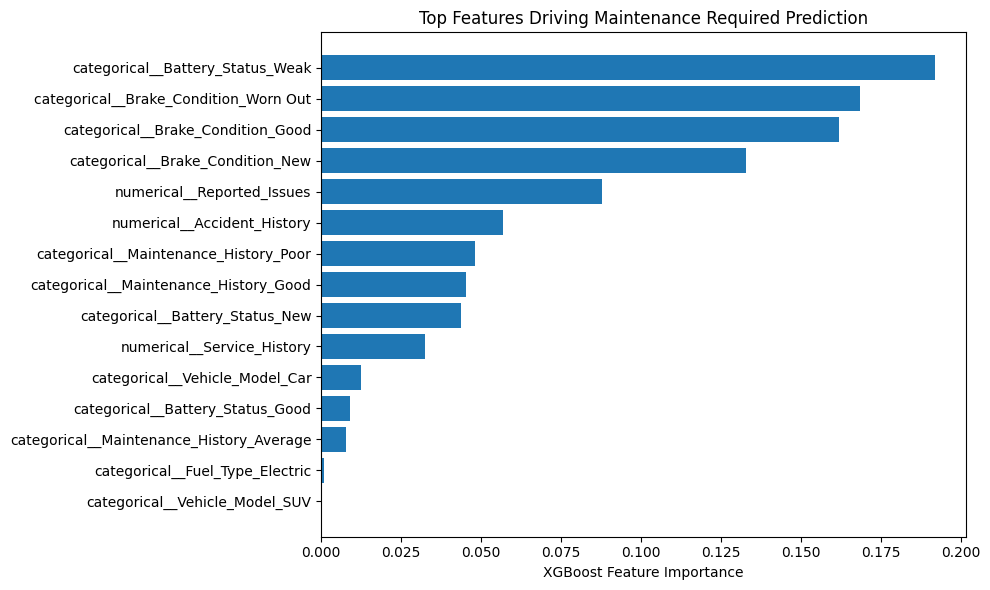

In [40]:
top_features = importance_df.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title(
    "Top Features Driving Maintenance Required Prediction"
)

plt.xlabel("XGBoost Feature Importance")

plt.tight_layout()
plt.show()

In [41]:
basic_features = [
    "Vehicle_Model",
    "Mileage",
    "Vehicle_Age",
    "Fuel_Type",
    "Transmission_Type",
    "Engine_Size",
    "Reported_Issues"
]

In [42]:
basic_unweighted_model, basic_unweighted_metrics = (
    train_xgb_for_features(
        basic_features,
        "Basic XGBoost - Unweighted"
    )
)

basic_unweighted_metrics

{'Model': 'Basic XGBoost - Unweighted',
 'Accuracy': 0.8093,
 'Balanced Accuracy': np.float64(0.5046036387264458),
 'Precision Positive': 0.8114251232022528,
 'Recall Positive': 0.9960493827160494,
 'Recall Negative': 0.013157894736842105,
 'Macro F1': 0.4599286760342656,
 'ROC AUC': np.float64(0.7756741065627031)}

In [43]:
X_basic_test = df[basic_features].iloc[test_idx]

basic_pred = basic_unweighted_model.predict(
    X_basic_test
)

print(
    classification_report(
        y_test,
        basic_pred,
        target_names=[
            "No Maintenance",
            "Maintenance Required"
        ],
        zero_division=0
    )
)

                      precision    recall  f1-score   support

      No Maintenance       0.44      0.01      0.03      1900
Maintenance Required       0.81      1.00      0.89      8100

            accuracy                           0.81     10000
           macro avg       0.63      0.50      0.46     10000
        weighted avg       0.74      0.81      0.73     10000



In [44]:
validation_results = pd.DataFrame([
    shallow_metrics,
    full_metrics,
    no_battery_metrics,
    no_bb_metrics,
    reduced_metrics,
    basic_unweighted_metrics,
    shuffle_metrics
])

validation_results

,Model,Accuracy,Balanced Accuracy,Precision Positive,Recall Positive,Recall Negative,Macro F1,ROC AUC
0,Shallow Decision Tree,0.9272,0.910949,0.971959,0.937160,0.884737,0.888124,0.962312
1,Full Enriched XGBoost,1.0000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
2,Without Battery Status,0.9031,0.933337,0.995277,0.884568,0.982105,0.865268,0.943445
3,Without Battery + Brake,0.8001,0.545052,0.824763,0.956420,0.133684,0.544179,0.853098
4,Reduced Condition Model,0.8077,0.532622,0.820417,0.976296,0.088947,0.520543,0.829655
5,Basic XGBoost - Unweighted,0.8093,0.504604,0.811425,0.996049,0.013158,0.459929,0.775674
6,Shuffled Target XGBoost,0.8102,0.500000,0.810200,1.000000,0.000000,0.447575,0.503538


In [45]:
validation_percent = validation_results.copy()

metric_cols = [
    "Accuracy",
    "Balanced Accuracy",
    "Precision Positive",
    "Recall Positive",
    "Recall Negative",
    "Macro F1",
    "ROC AUC"
]

for col in metric_cols:
    validation_percent[col] = (
        validation_percent[col] * 100
    ).round(2)

validation_percent

,Model,Accuracy,Balanced Accuracy,Precision Positive,Recall Positive,Recall Negative,Macro F1,ROC AUC
0,Shallow Decision Tree,92.72,91.09,97.20,93.72,88.47,88.81,96.23
1,Full Enriched XGBoost,100.00,100.00,100.00,100.00,100.00,100.00,100.00
2,Without Battery Status,90.31,93.33,99.53,88.46,98.21,86.53,94.34
3,Without Battery + Brake,80.01,54.51,82.48,95.64,13.37,54.42,85.31
4,Reduced Condition Model,80.77,53.26,82.04,97.63,8.89,52.05,82.97
5,Basic XGBoost - Unweighted,80.93,50.46,81.14,99.60,1.32,45.99,77.57
6,Shuffled Target XGBoost,81.02,50.00,81.02,100.00,0.00,44.76,50.35


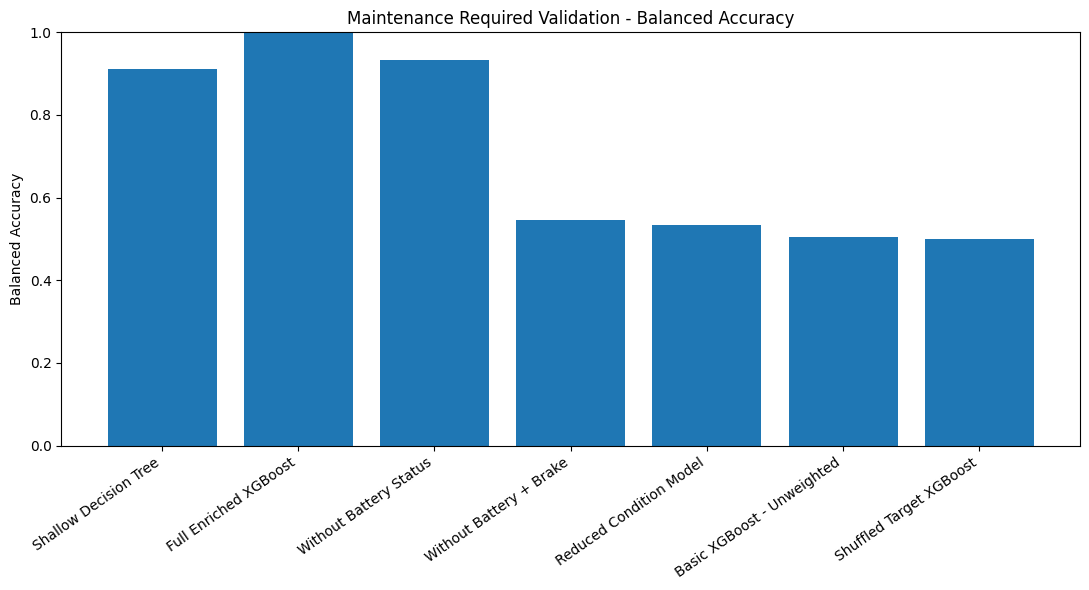

In [46]:
plt.figure(figsize=(11, 6))

plt.bar(
    validation_results["Model"],
    validation_results["Balanced Accuracy"]
)

plt.title(
    "Maintenance Required Validation - Balanced Accuracy"
)

plt.ylabel("Balanced Accuracy")
plt.ylim(0, 1)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()
plt.show()

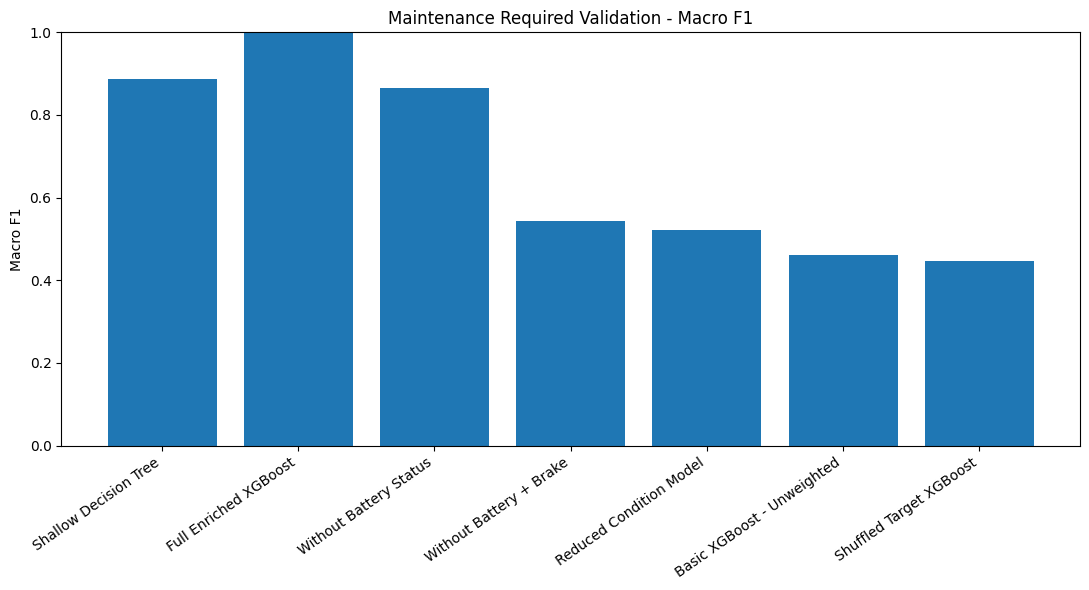

In [47]:
plt.figure(figsize=(11, 6))

plt.bar(
    validation_results["Model"],
    validation_results["Macro F1"]
)

plt.title(
    "Maintenance Required Validation - Macro F1"
)

plt.ylabel("Macro F1")
plt.ylim(0, 1)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()
plt.show()

In [48]:
results_dir = "/content/drive/MyDrive/AutoSenseAI/results"

os.makedirs(
    results_dir,
    exist_ok=True
)

In [49]:
validation_results.to_csv(
    os.path.join(
        results_dir,
        "maintenance_need_leakage_validation.csv"
    ),
    index=False
)

In [50]:
importance_df.to_csv(
    os.path.join(
        results_dir,
        "maintenance_need_feature_importance.csv"
    ),
    index=False
)

## Leakage and Dataset-Structure Validation

Purpose:

The previous enriched Random Forest and XGBoost models achieved 100%
performance on the held-out dataset. This experiment investigates whether
that performance reflects genuine predictive information, a strongly
structured/synthetic target-generation rule, or unintended information
leakage.

Validation performed:

1. Examined conditional maintenance rates for important condition features.
2. Tested individual features independently.
3. Trained a shallow decision tree to discover simple predictive rules.
4. Performed feature-ablation experiments.
5. Removed high-importance condition variables and measured performance loss.
6. Performed a shuffled-target sanity check.
7. Checked duplicate predictor patterns.
8. Re-evaluated models using Balanced Accuracy and Macro F1.
9. Re-trained the Basic XGBoost model without inappropriate positive-class weighting.

Interpretation:

[Complete after observing the results.]

Important limitation:

Perfect performance on a synthetic or highly structured benchmark dataset
must not be interpreted as guaranteed real-world vehicle-maintenance
accuracy. Further validation with real workshop records is required.